# 41 · Forms head to head

**Question.** Case by case, where does the descriptor form cost less than the standard form, and by how much?

In [1]:
from pathlib import Path

from pihm import plotting
from pihm.pipeline.results import Results

results = Results.at(Path("..").resolve())
CAMPAIGNS = ("p5_t3", "p2_reproduction", "p5_build")
plotting.apply_style()
print(results.describe(CAMPAIGNS))

p5_t3: 192 records, 192 ok
p2_reproduction: 327 records, 327 ok
p5_build: 224 records, 224 ok


In [2]:
from IPython.display import Markdown, display

from pihm.pipeline.results import cost_comparison

table = cost_comparison(
    (results.rows("p5_t3", regime="standard"), results.rows("p2_reproduction")),
    (results.rows("p5_t3", regime="descriptor"), results.rows("p5_build")),
)
trusted = [row for row in table if row["trusted"]]


def crossover(problem):
    """Return the least n from which the descriptor costs less at every trusted n, or None."""
    points = sorted((row["n"], row["total"]) for row in trusted if row["problem"] == problem)
    return min((n for n, _ in points if all(r > 1.0 for m, r in points if m >= n)), default=None)


def number(value):
    """Return a ratio to three significant figures, with no exponent."""
    return f"{value:,.0f}" if value >= 1000 else f"{value:.3g}"


problems = sorted({row["problem"] for row in trusted})
first = {p: min(r["n"] for r in trusted if r["problem"] == p) for p in problems}
last = {p: max((r for r in trusted if r["problem"] == p), key=lambda r: r["n"]) for p in problems}
groups = {}
for problem in problems:
    n = crossover(problem)
    groups.setdefault("every" if n == first[problem] else n, []).append(problem)


def span(column):
    """Return the range of a ratio over each problem's largest trusted n."""
    values = [row[column] for row in last.values()]
    return f"{number(min(values))} to {number(max(values))}"


cheaper = sum(row["total"] > 1.0 for row in trusted)
lines = [f"- The descriptor costs fewer cx in {cheaper} of the {len(trusted)} trusted cases."]
if "every" in groups:
    lines.append(f"- It costs less at every trusted n for {', '.join(groups['every'])}.")
for n, names in sorted((k, v) for k, v in groups.items() if isinstance(k, int)):
    lines.append(f"- It costs less from n = {n} on for {', '.join(names)}.")
if None in groups:
    lines.append(f"- It never costs less for {', '.join(groups[None])}.")
lines.append(
    f"- At each problem's largest trusted n, the standard form costs {span('total')} times the "
    f"descriptor's cx: its filter degree is {span('degree')} times the descriptor's, and its "
    f"walk step {span('step')} times."
)
display(Markdown("\n".join(lines)))

- The descriptor costs fewer cx in 68 of the 73 trusted cases.
- It costs less at every trusted n for R1, R2a, R2b, R2c, R3c, R4a, R4b, R4c, R4d, R5c.
- It costs less from n = 4 on for R3a, R3b, R3d, R5a.
- It costs less from n = 5 on for R5b.
- At each problem's largest trusted n, the standard form costs 1.16 to 1,278,225 times the descriptor's cx: its filter degree is 3.26 to 2,062,465 times the descriptor's, and its walk step 0.346 to 1.91 times.

The standard form's total cx over the descriptor's, from the resource estimates (T3), against
n. Above the break-even line the descriptor costs less. The panels share their y-axis.

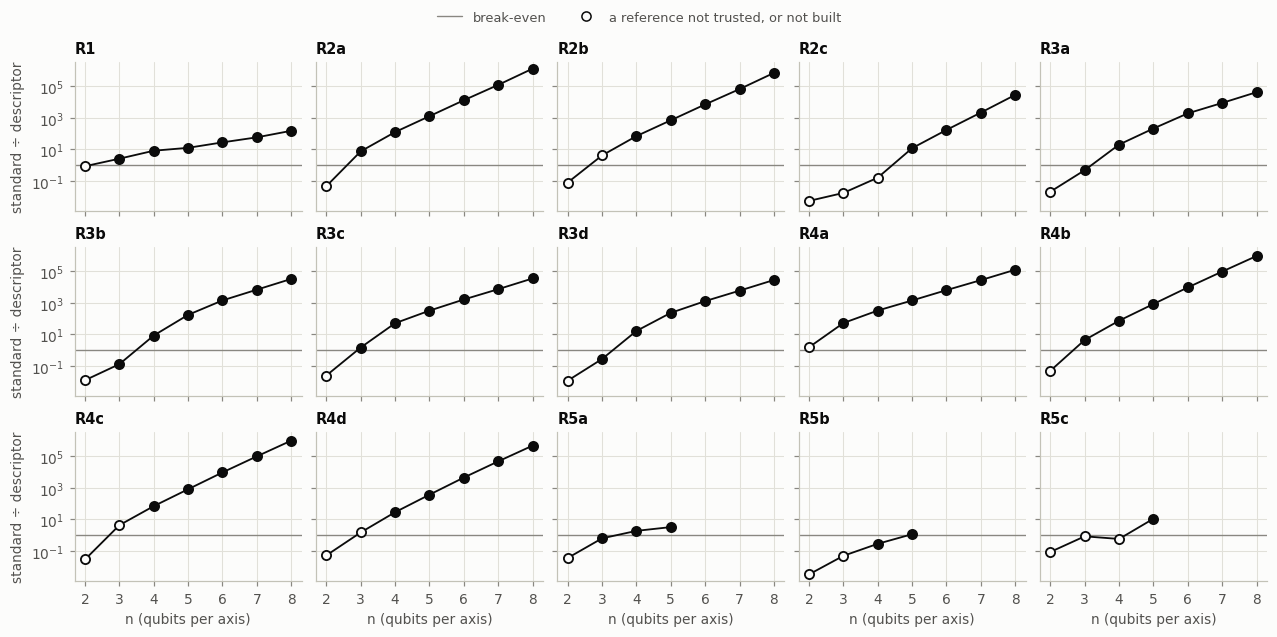

In [3]:
plotting.cost_ratios(table);

The same ratio at each problem's largest n, and its three factors: the preparations that
amplitude amplification needs, the filter's degree, and the cx of one walk step. The total is
their product.

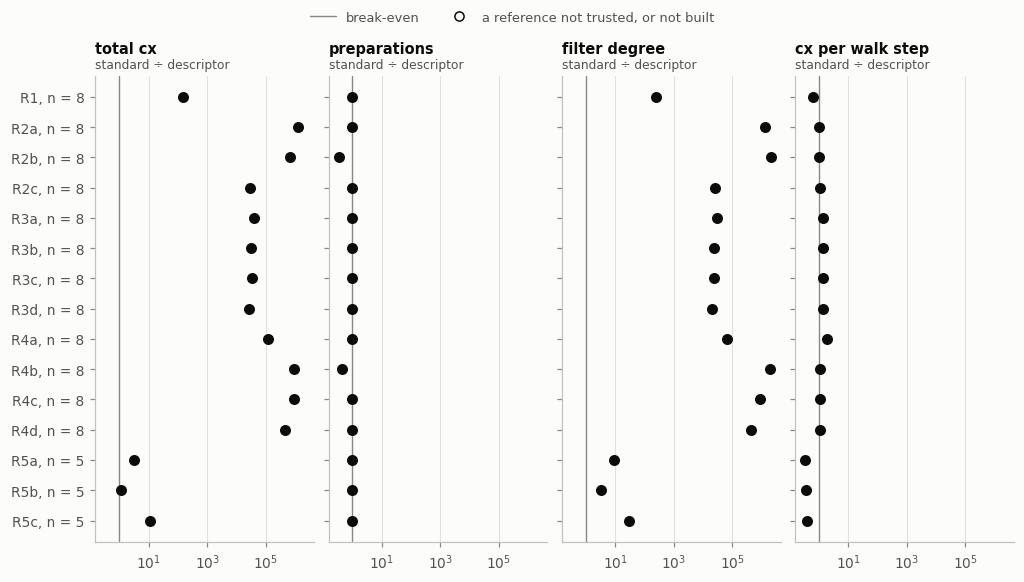

In [4]:
plotting.cost_factors(table);

**What this does not show.** These are resource estimates, not simulations, under the minimax filter
in both forms. R1–R5 are compared as the descriptor runs them, never as the paper printed them. A hollow case compares references that are not trusted.